In [202]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor, Lasso, Ridge
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
import math


In [203]:
# Read in Data from housing.csv 
data = pd.read_csv("housing.csv")
data.head()

,RM,LSTAT,PTRATIO,MEDV
0,6.575,4.98,15.3,504000.0
1,6.421,9.14,17.8,453600.0
2,7.185,4.03,17.8,728700.0
3,6.998,2.94,18.7,701400.0
4,7.147,5.33,18.7,760200.0


In [204]:
data.describe()

,RM,LSTAT,PTRATIO,MEDV
count,489.000000,489.000000,489.000000,4.890000e+02
mean,6.240288,12.939632,18.516564,4.543429e+05
std,0.643650,7.081990,2.111268,1.653403e+05
min,3.561000,1.980000,12.600000,1.050000e+05
25%,5.880000,7.370000,17.400000,3.507000e+05
50%,6.185000,11.690000,19.100000,4.389000e+05
75%,6.575000,17.120000,20.200000,5.187000e+05
max,8.398000,37.970000,22.000000,1.024800e+06


In [205]:
data.isnull().sum()

RM         0
LSTAT      0
PTRATIO    0
MEDV       0
dtype: int64

In [206]:
data.columns

Index(['RM', 'LSTAT', 'PTRATIO', 'MEDV'], dtype='str')

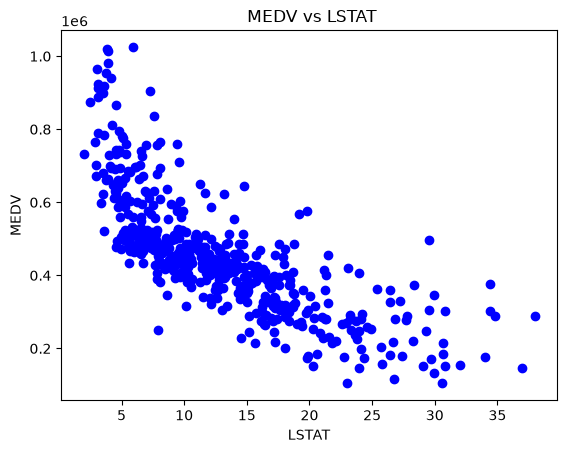

In [207]:
# Visualize the  relation of MEDV and LSTAT using a scatter plot 
plt.scatter(data['LSTAT'], data['MEDV'], color="blue")
plt.title(" MEDV vs LSTAT")
plt.xlabel("LSTAT")
plt.ylabel("MEDV")
plt.show()

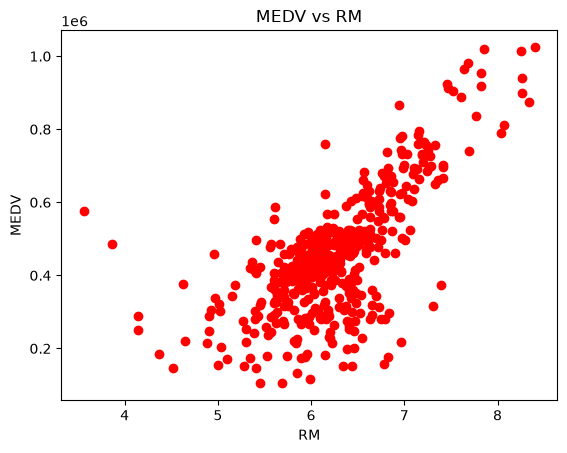

In [208]:
# Visualize the relation of MEDV and RM using a scatter plot
plt.scatter(data['RM'], data['MEDV'], color="red")
plt.title("MEDV vs RM")
plt.xlabel("RM")
plt.ylabel("MEDV")
plt.show()

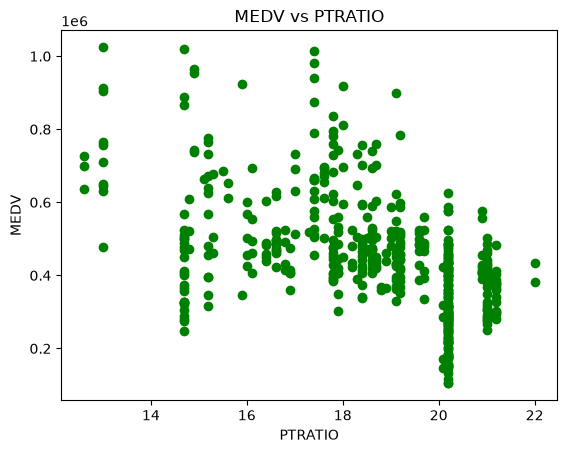

In [209]:
# Visualize the relation of MEDV and PTRATIO using a scatter plot
plt.scatter(data['PTRATIO'], data['MEDV'],color="green")
plt.title("MEDV vs PTRATIO")
plt.xlabel("PTRATIO")
plt.ylabel("MEDV")
plt.show()

In [210]:
# Split the data into features and target
X = data.drop(["MEDV"], axis=1)
y = data['MEDV']

In [211]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=0)


In [212]:
y_test.shape

(98,)

In [213]:
X_train

,RM,LSTAT,PTRATIO
447,6.209,13.22,20.2
457,5.427,18.14,20.2
386,5.349,19.77,20.2
361,6.380,23.69,20.2
221,6.552,3.76,17.4
...,...,...,...
323,6.310,6.75,20.2
192,7.274,6.62,12.6
117,6.021,10.30,17.8
47,6.030,18.80,17.9


In [214]:
### Scaled X_train and X_test 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [215]:
X_train_scaled

array([[-0.03187316,  0.04649813,  0.78568433],
       [-1.24840058,  0.74833711,  0.78568433],
       [-1.36974219,  0.98085693,  0.78568433],
       ...,
       [-0.32433755, -0.37004046, -0.36758671],
       [-0.3103366 ,  0.84248624, -0.31953375],
       [-0.32589321, -0.39714399, -0.94422223]], shape=(391, 3))

##### Linear Regression

In [216]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 52794.95,-80836.91,-40424.54]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.526e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[26.97,17.03,12.46]"


In [217]:
# Evaluate model 
y_pred = model.predict(X_test_scaled)
y_pred

array([423881.77982895, 680175.69839647, 299260.7609394 , 392611.21769684,
       530004.11807904, 358978.92349417, 229712.66440934, 413822.48413948,
       476083.34393711, 372832.64164123, 317887.97119974, 356411.60848685,
       476957.35268889,  41708.57314634, 488212.51565249, 311735.06600882,
       464748.13475284, 614234.97752242, 381107.29958423, 654465.18193064,
       669847.67483837, 654791.28591213,   2659.32992511, 456701.79375367,
       360629.19475397, 754076.24345949, 710239.10831734, 753933.55327373,
       430146.73719046, 422726.63139321, 373193.31682792, 457577.73243125,
       473612.26260492, 682085.6544707 , 456621.35600982, 768574.93416341,
       521836.2114939 , 256253.31089372, 504441.5647348 , 593086.86820062,
       318422.2032469 , 442998.85574834, 403020.84592176, 500263.1969264 ,
       276278.07142632, 365727.12293787, 526527.28007971, 358009.74373423,
       716807.29324917, 407362.40304143, 680253.89384137, 447508.33823   ,
       615695.42331661, 3

In [218]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MAE: ",round(mae, 2))
print("MSE: ",round(mse, 2))
print("RMSE: ", round(math.sqrt(mse)))
print("R2: ", r2)

MAE:  72451.0
MSE:  9727501160.08
RMSE:  98628
R2:  0.6574622113312862


#### SGDRegressor

In [219]:
model = SGDRegressor()
model.fit(X_train_scaled, y_train)


,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None


In [220]:
# Evaluate model
y_pred = model.predict(X_test_scaled) 
y_pred

array([423623.45061852, 681144.04508586, 299404.2072836 , 392815.12686324,
       530307.08850972, 359000.83768652, 229643.31478466, 413745.62837379,
       476253.95348759, 372610.9965895 , 317827.69779808, 356212.44086077,
       476927.80710187,  40954.52749116, 488327.32763307, 311396.90040865,
       464893.5502473 , 614893.87169279, 381056.45577597, 655175.98490912,
       671001.02019633, 655483.26250532,   1852.31908665, 456630.98378726,
       360423.10657214, 755194.07739626, 711405.89617336, 755056.9354487 ,
       430183.98165467, 422711.92308904, 373249.74075834, 457905.13045244,
       473701.30491936, 682930.92809021, 456746.331203  , 769725.48371856,
       522117.34390926, 255945.23884381, 504644.65935956, 593512.76698953,
       318350.45783097, 443511.24419913, 402841.97586609, 500421.09988655,
       275979.43649027, 365517.35134024, 526830.84263959, 357945.79729151,
       717750.66658306, 407307.44624575, 681089.20268439, 447508.3062623 ,
       616295.35615126, 3

In [221]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MAE: ",round(mae, 2))
print("MSE: ",round(mse, 2))
print("RMSE: ", round(math.sqrt(mse)))
print("R2: ", r2)

MAE:  72506.57
MSE:  9729522709.65
RMSE:  98638
R2:  0.6573910258226108


#### Lasso

In [222]:
model = Lasso()
model.fit(X_train_scaled, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [223]:
# Evaluate model 
y_pred = model.predict(X_test_scaled)
y_pred

array([423881.87814663, 680173.25118334, 299260.00653158, 392613.34116467,
       530003.49118862, 358980.57759934, 229711.71583966, 413823.02583438,
       476082.85541502, 372833.51310419, 317889.71727936, 356412.24316495,
       476956.97604984,  41710.26624567, 488213.56354293, 311736.2352497 ,
       464748.12877958, 614232.97432276, 381107.27629221, 654463.28821975,
       669846.22706271, 654790.50538577,   2661.22977096, 456701.19080441,
       360629.07687555, 754074.91219759, 710237.25041864, 753932.11598257,
       430147.62901503, 422726.69343061, 373194.96797582, 457576.3287754 ,
       473612.15308608, 682083.73994157, 456621.34835628, 768575.2636275 ,
       521834.97357725, 256254.60378824, 504441.2998136 , 593085.28044443,
       318423.88859645, 442998.5013689 , 403020.62793388, 500262.83351389,
       276278.50394385, 365727.59797024, 526526.69679635, 358011.0016016 ,
       716808.38596526, 407362.45428404, 680252.0875422 , 447507.77703224,
       615693.99434987, 3

In [224]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MAE: ",round(mae, 2))
print("MSE: ",round(mse, 2))
print("RMSE: ", round(math.sqrt(mse)))
print("R2: ", r2)

MAE:  72450.78
MSE:  9727469406.59
RMSE:  98628
R2:  0.6574633294778504


#### Ridge

In [225]:
model = Ridge()
model.fit(X_train_scaled, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [226]:
# Evaluate model 
y_pred = model.predict(X_test_scaled)
y_pred

array([423807.18422544, 679925.42900886, 299597.94207578, 392801.37762582,
       529880.5956177 , 359173.02402509, 230127.62449022, 413841.75892636,
       476035.94730391, 372897.2531056 , 318146.56166941, 356517.80095564,
       476838.11314343,  42340.42248961, 488140.06975939, 311899.92209243,
       464724.2299975 , 614029.05822353, 381201.36444365, 654188.80539418,
       669701.17085893, 654523.52783098,   3363.16742718, 456610.15286823,
       360712.55065217, 753729.09588477, 710000.54034941, 753587.17735916,
       430175.06831783, 422741.12857557, 373367.69673744, 457614.78618474,
       473546.76939319, 681794.81906951, 456608.42378922, 768230.81261263,
       521714.45452214, 256555.61994806, 504345.15122309, 592851.3436075 ,
       318674.61624805, 443149.96264875, 403017.03198075, 500158.62720234,
       276526.2391207 , 365806.24815696, 526412.42708012, 358169.63628152,
       716516.75215562, 407396.96135718, 679965.18659405, 447463.27991268,
       615473.44942411, 3

In [227]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MAE: ",round(mae, 2))
print("MSE: ",round(mse, 2))
print("RMSE: ", round(math.sqrt(mse)))
print("R2: ", r2)

MAE:  72418.87
MSE:  9721645392.35
RMSE:  98598
R2:  0.6576684124612746


#### SVR

In [228]:
model = SVR()
model.fit(X_train_scaled, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [229]:
# Evaluate model 
y_pred = model.predict(X_test_scaled)
y_pred

array([436808.1671777 , 436863.51015338, 436818.73776484, 436791.64313467,
       436882.25997287, 436768.11090649, 436821.88937537, 436794.0960487 ,
       436847.46380614, 436775.84561693, 436758.54199462, 436767.21174152,
       436837.85609266, 436813.99024212, 436835.98699895, 436760.19741882,
       436835.40579036, 436884.05078445, 436787.83064052, 436894.67983661,
       436854.85800488, 436903.84404275, 436818.98955885, 436828.18593788,
       436781.41919197, 436868.39126756, 436858.92806338, 436868.05214404,
       436802.51816045, 436804.39100715, 436773.99906005, 436837.12560297,
       436839.47374423, 436887.07459949, 436829.67730147, 436849.71456465,
       436874.15764663, 436758.06353751, 436863.47167081, 436898.77886864,
       436757.57200684, 436832.1903601 , 436797.30929555, 436859.7458715 ,
       436770.12067171, 436772.85466888, 436880.4594587 , 436763.6007889 ,
       436848.79553222, 436795.75986343, 436889.60224784, 436825.60363842,
       436902.92092379, 4

In [230]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MAE: ",round(mae, 2))
print("MSE: ",round(mse, 2))
print("RMSE: ", round(math.sqrt(mse)))
print("R2: ", r2)

MAE:  120610.67
MSE:  28977783167.29
RMSE:  170229
R2:  -0.020404480379341727


#### KNeighborsRegressor

In [231]:
model = KNeighborsRegressor(n_neighbors=5)
model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [232]:
# Evaluate model 
y_pred = model.predict(X_test_scaled)
y_pred

array([419580., 707700., 324240., 277200., 463680., 258300., 326760.,
       441840., 462000., 362460., 273420., 339780., 457380., 212940.,
       485520., 346920., 458640., 526260., 420420., 636720., 748860.,
       723660., 226800., 448560., 413280., 869400., 748860., 869400.,
       391440., 411180., 276780., 388500., 463680., 691740., 448980.,
       895440., 460740., 187320., 486780., 501480., 273420., 396900.,
       458220., 468720., 325920., 395220., 463680., 376320., 895440.,
       414960., 703920., 397740., 593040., 300300., 706440., 525420.,
       374220., 310800., 459900., 434280., 400260., 254940., 404040.,
       391440., 391020., 425040., 220500., 534660., 530040., 275100.,
       196140., 570780., 367920., 523740., 271740., 407820., 544740.,
       316680., 539280., 292740., 425880., 781620., 446460., 502320.,
       445200., 691740., 545580., 489720., 417480., 396900., 439740.,
       324240., 330120., 296940., 476280., 522060., 417060., 537180.])

In [233]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MAE: ",round(mae, 2))
print("MSE: ",round(mse, 2))
print("RMSE: ", round(math.sqrt(mse)))
print("R2: ", r2)

MAE:  59734.29
MSE:  6309295200.0
RMSE:  79431
R2:  0.7778286540088801
